# Graph neural network classification of early sexual debut among Ethiopian women (2024/2025 EDHS)
**Revised analysis for the manuscript revision (Scientific Reports).** Everything reported in the manuscript is produced by this notebook.

**What changed relative to the first submission (reviewer comments in brackets)**
* One row per woman. The extract is birth-expanded (several rows per woman); the earlier "55,620" counted birth-level records, not women (R1-1, R2-1, R3).
* Design-weighted prevalence with a PSU-within-stratum bootstrap CI (R1-7/8, R2-2).
* **Cluster-level** train / validation / test split. Training, validation and test graphs are built separately, so no test woman is ever connected to a training woman: the evaluation is inductive (R1-4/5, R2-5, R3).
* **All** models share the same split, thresholds and test clusters (R1-9, R2-4).
* GCN is compared with GraphSAGE and GAT, a graph-free MLP control, and the logistic-regression / SVM / decision-tree reference models (R1-10/11, R2-13). Stronger tabular learners (random forest, XGBoost, LightGBM, CatBoost) are left as future work and stated as a limitation.
* Cluster-bootstrap 95% CIs, paired AUC differences, calibration slope / intercept, Brier score, five repeated splits (R1-12, R2-9/14).
* Global Moran's I on cluster prevalence and on model residuals (R1-14).
* Repeated-permutation predictor importance, interpreted as predictive importance only (R2-8, R3).

**Runtime:** about 15-30 min on Colab CPU. **Inputs (read from Google Drive, `MyDrive/DHIS`):** `data_3.csv` (EDHS women's extract) and `ETGE8AFL.dbf` (DHS GPS attribute table; cluster coordinates are displaced by the DHS Program and are used only for cluster-level spatial statistics, never for distances to facilities).

## 0. Install (PyTorch is pre-installed on Colab)

In [ ]:
!pip -q install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 31.5 MB/s eta 0:00:00


## 1. Configuration and inputs

In [ ]:
import os, json, time, random, warnings
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')

SEED_PRIMARY = 2026                     # primary cluster-level split and all model seeds
REPEAT_SEEDS = [11, 12, 13, 14, 15]     # five additional random cluster-level splits (robustness)
N_BOOT = 1000                           # cluster-bootstrap resamples of the held-out test clusters
N_PERM_REPEATS = 30                     # permutations per predictor
random.seed(SEED_PRIMARY); np.random.seed(SEED_PRIMARY)

# Mount Google Drive; the input files are in MyDrive/DHIS
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DIR = '/content/drive/MyDrive/DHIS'
except ImportError:
    DIR = '.'
DATA_PATH, GPS_DBF_PATH = f'{DIR}/data_3.csv', f'{DIR}/ETGE8AFL.dbf'   # DHS women's extract and DHS GPS attribute table
for p in (DATA_PATH, GPS_DBF_PATH):
    if not os.path.exists(p):
        raise FileNotFoundError(p + ' not found. Files in folder: ' + str(os.listdir(DIR) if os.path.isdir(DIR) else DIR))
os.chdir('/content' if os.path.isdir('/content') else '.')   # outputs (results.json, figures/) are written here

Mounted at /content/drive


## 2. Helper functions (DBF reader, preprocessing, metrics, cluster bootstrap, Moran's I, design-weighted prevalence)

In [ ]:
import struct
def read_dbf(path):
    with open(path,'rb') as f:
        h=f.read(32); n=struct.unpack('<I',h[4:8])[0]; hl=struct.unpack('<H',h[8:10])[0]; rl=struct.unpack('<H',h[10:12])[0]
        fields=[]
        while True:
            d=f.read(32)
            if d[0]==0x0D: break
            fields.append((d[:11].split(b'\0')[0].decode(),chr(d[11]),d[16]))
        f.seek(hl); rows=[]
        for _ in range(n):
            r=f.read(rl)
            if r[0]==0x2A: continue
            o=1; row={}
            for nm,t,l in fields:
                v=r[o:o+l].decode('latin1').strip(); o+=l
                row[nm]=v
            rows.append(row)
    df=pd.DataFrame(rows)
    for c in ['DHSCLUST','LATNUM','LONGNUM','DHSREGCO','ALT_GPS','ALT_DEM']:
        if c in df: df[c]=pd.to_numeric(df[c],errors='coerce')
    return df


import numpy as np, pandas as pd, json, warnings
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix
warnings.filterwarnings('ignore')

NUM = ['educ_level','educ_years','wealth','read_news','listen_radio','watch_tv','residence']
CAT = ['region','literacy','water','toilet','fuel']
PRED_LABELS = {'educ_level':'Education level','educ_years':'Years of education','wealth':'Wealth index',
 'read_news':'Reads newspaper','listen_radio':'Listens to radio','watch_tv':'Watches television','residence':'Residence',
 'region':'Region','literacy':'Literacy','water':'Drinking-water source','toilet':'Toilet facility','fuel':'Cooking fuel'}
WATER={'11':'Piped into dwelling','12':'Piped to yard/plot','13':'Piped to neighbour','14':'Public tap/standpipe','21':'Tube well/borehole','31':'Protected well','32':'Unprotected well','41':'Protected spring','42':'Unprotected spring','43':'River/dam/lake/pond','51':'Rainwater','61':'Tanker truck','62':'Cart with small tank','71':'Bottled water','72':'Large bottle','Other':'Other'}
TOILET={'12':'Flush to piped sewer','13':'Flush to septic tank','21':'Ventilated improved pit latrine','22':'Pit latrine with slab','23':'Pit latrine without slab/open pit','31':'No facility/bush/field','Other':'Other'}
FUEL={'1':'Electricity','10':'Charcoal','11':'Wood','14':'Animal dung/waste','Other':'Other'}

def cluster_split(d, seed, frac=(0.7,0.1,0.2)):
    """region-stratified random assignment of whole clusters to train/val/test"""
    rng=np.random.default_rng(seed)
    cl=d.groupby('cluster').region.first().reset_index()
    assign={}
    for reg,g in cl.groupby('region'):
        ids=g.cluster.values.copy(); rng.shuffle(ids); n=len(ids)
        nt=int(round(frac[2]*n)); nv=int(round(frac[1]*n))
        for i,c in enumerate(ids):
            assign[c]='test' if i<nt else ('val' if i<nt+nv else 'train')
    s=d.cluster.map(assign)
    return (s=='train').values,(s=='val').values,(s=='test').values

def make_pre():
    return ColumnTransformer([
      ('num',Pipeline([('imp',SimpleImputer(strategy='median')),('sc',StandardScaler())]),NUM),
      ('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),CAT)])

def feature_groups(pre):
    names=pre.get_feature_names_out()
    groups={}
    for i,n in enumerate(names):
        base=n.split('__',1)[1]
        g=base if base in NUM else next(c for c in CAT if base.startswith(c+'_'))
        groups.setdefault(g,[]).append(i)
    return groups, names

def calib(y,p):
    p=np.clip(p,1e-6,1-1e-6); lg=np.log(p/(1-p)).reshape(-1,1)
    m=LogisticRegression(penalty=None,max_iter=1000).fit(lg,y)
    # calibration-in-the-large: intercept with slope fixed at 1 (offset) via Newton
    a=0.0
    for _ in range(50):
        q=1/(1+np.exp(-(lg[:,0]+a))); g=(y-q).sum(); h=(q*(1-q)).sum(); a+=g/h
    return float(a), float(m.coef_[0,0]), float(m.intercept_[0])  # CITL, slope, intercept(free slope)

def recalibrate(p_val, y_val, p_new):
    """Logistic recalibration fitted on validation predictions, applied to p_new."""
    f = lambda p: np.log(np.clip(p, 1e-6, 1-1e-6)/(1-np.clip(p, 1e-6, 1-1e-6))).reshape(-1, 1)
    m = LogisticRegression(penalty=None, max_iter=1000).fit(f(p_val), y_val)
    return m.predict_proba(f(p_new))[:, 1]

def metrics_at(y,p,thr):
    yh=(p>=thr).astype(int); tn,fp,fn,tp=confusion_matrix(y,yh,labels=[0,1]).ravel()
    sens=tp/(tp+fn); spec=tn/(tn+fp); prec=tp/(tp+fp) if tp+fp else 0
    return dict(accuracy=(tp+tn)/len(y),sensitivity=sens,specificity=spec,precision=prec,
                f1=2*prec*sens/(prec+sens) if prec+sens else 0,balanced_accuracy=(sens+spec)/2,tp=int(tp),fp=int(fp),tn=int(tn),fn=int(fn))

def youden_threshold(y,p):
    ts=np.unique(np.quantile(p,np.linspace(0.01,0.99,197)))
    best=max(ts,key=lambda t:(lambda m:m['sensitivity']+m['specificity'])(metrics_at(y,p,t)))
    return float(best)

def full_metrics(y,p,thr,w=None):
    m=metrics_at(y,p,thr)
    m['auc']=roc_auc_score(y,p); m['pr_auc']=average_precision_score(y,p); m['brier']=brier_score_loss(y,p)
    citl,slope,_=calib(y,p); m['calib_citl']=citl; m['calib_slope']=slope
    if w is not None: m['auc_weighted']=roc_auc_score(y,p,sample_weight=w)
    return m

def cluster_boot(y,probs,clusters,B=1000,seed=7):
    """probs: dict name->array. Paired cluster bootstrap of test set. Returns CIs for AUC and pairwise AUC differences."""
    rng=np.random.default_rng(seed); uc=np.unique(clusters); idx={c:np.where(clusters==c)[0] for c in uc}
    names=list(probs); auc={n:[] for n in names}; brier={n:[] for n in names}
    for _ in range(B):
        sel=rng.choice(uc,len(uc),replace=True); ii=np.concatenate([idx[c] for c in sel]); yy=y[ii]
        if yy.min()==yy.max(): continue
        for n in names:
            auc[n].append(roc_auc_score(yy,probs[n][ii])); brier[n].append(brier_score_loss(yy,probs[n][ii]))
    out={'auc_ci':{n:[float(np.percentile(auc[n],2.5)),float(np.percentile(auc[n],97.5))] for n in names},
         'brier_ci':{n:[float(np.percentile(brier[n],2.5)),float(np.percentile(brier[n],97.5))] for n in names},'diff':{}}
    for i,a in enumerate(names):
        for b in names[i+1:]:
            dlt=np.array(auc[a])-np.array(auc[b]);
            pv=2*min((dlt<=0).mean(),(dlt>=0).mean()); pv=max(pv,1/len(dlt))
            out['diff'][f'{a} vs {b}']=dict(mean=float(dlt.mean()),lo=float(np.percentile(dlt,2.5)),hi=float(np.percentile(dlt,97.5)),p=float(pv))
    return out

def haversine_matrix(lat,lon):
    la=np.radians(lat); lo=np.radians(lon)
    dla=la[:,None]-la[None,:]; dlo=lo[:,None]-lo[None,:]
    a=np.sin(dla/2)**2+np.cos(la)[:,None]*np.cos(la)[None,:]*np.sin(dlo/2)**2
    return 2*6371*np.arcsin(np.sqrt(a))

def knn_weights(D,k):
    n=len(D); W=np.zeros((n,n));
    for i in range(n):
        o=np.argsort(D[i]); o=o[o!=i][:k]; W[i,o]=1
    return W/W.sum(1,keepdims=True)

def morans_I(x,W,perm=9999,seed=3):
    z=x-x.mean(); n=len(x); S0=W.sum()
    I=(n/S0)*(z@W@z)/(z@z)
    rng=np.random.default_rng(seed); cnt=0
    for _ in range(perm):
        zp=rng.permutation(z); cnt+= ((n/S0)*(zp@W@zp)/(zp@zp))>=I
    p=(cnt+1)/(perm+1); EI=-1/(n-1)
    return float(I),float(EI),float(p)

def weighted_prev(d, mask=None, B=1000, seed=11):
    """Design-weighted prevalence; 95% CI from a PSU-within-stratum bootstrap (Hajek ratio estimator)."""
    x=d if mask is None else d[mask]
    est=np.average(x.early_debut,weights=x.wt)
    rng=np.random.default_rng(seed); arrs=[]
    for _,g in x.groupby('strata'):
        t=g.assign(n=g.wt*g.early_debut).groupby('psu')[['n','wt']].sum().values; arrs.append(t)
    stats=[]
    for _ in range(B):
        num=den=0.0
        for a in arrs:
            k=len(a)
            if k<2: num+=a[:,0].sum(); den+=a[:,1].sum(); continue
            p=rng.integers(0,k,k); num+=a[p,0].sum(); den+=a[p,1].sum()
        stats.append(num/den)
    return float(est),float(np.percentile(stats,2.5)),float(np.percentile(stats,97.5))

## 3. Analytic dataset: one row per woman, outcome, 12 predictors, cluster coordinates

In [ ]:
# ---- Build the analytic dataset: one row per woman (caseid), outcome, 12 predictors, cluster GPS ----
gps = read_dbf(GPS_DBF_PATH)                      # DHS GPS attribute table (797 clusters; DHSCLUST == v001)
cols = ['caseid','v001','v005','v021','v023','v024','v025','v106','v133','v155','v157','v158','v159',
        'v113','v116','v161','v190','v012','v525']
raw = pd.read_csv(DATA_PATH, usecols=cols)
flow = {'records_in_extract': len(raw)}
raw = raw[raw.v525.between(5, 49)]                # drop 'never had sex' / not applicable / missing codes (none in this extract)
flow['records_with_valid_age_first_sex'] = len(raw)
# The extract is birth-expanded (several rows per woman). Woman-level variables are constant within caseid,
# so we keep one row per woman. (Checked: v525, v012, v106, v190 never vary within caseid.)
df = raw.drop_duplicates('caseid').copy()
flow['unique_women'] = len(df); flow['clusters'] = int(df.v001.nunique())
df['early_debut'] = (df.v525 < 18).astype(int)    # age at first sexual intercourse < 18 years
reg = dict(zip(gps.DHSREGCO.astype(int), gps.DHSREGNA))
d = pd.DataFrame({'caseid': df.caseid, 'cluster': df.v001, 'psu': df.v021, 'strata': df.v023, 'wt': df.v005/1e6,
                  'age': df.v012, 'age_first_sex': df.v525, 'early_debut': df.early_debut})
d['region'] = df.v024.map(reg)
d['residence'] = (df.v025 == 2).astype(int)       # 1 = rural
d['educ_level'] = df.v106; d['educ_years'] = df.v133.astype(float); d['wealth'] = df.v190
d['read_news'] = df.v157; d['listen_radio'] = df.v158; d['watch_tv'] = df.v159
d['literacy'] = df.v155.map({0:'Cannot read at all',1:'Reads parts of sentence',2:'Reads whole sentence',
                             3:'No card with required language',4:'Blind/visually impaired'})
def _clean(s, codes):                              # DHS special codes (not de jure resident, other, missing) -> NaN
    return s.where(~s.isin(codes)).astype('Int64').astype(str).replace('<NA>', np.nan)
d['water'] = _clean(df.v113, [96,97,99]); d['toilet'] = _clean(df.v116, [96,97,99]); d['fuel'] = _clean(df.v161, [95,96,97,99])
for c in ['water','toilet','fuel']:                # categories with <1% of observed values are pooled into "Other"
    vc = d[c].value_counts(normalize=True); rare = vc[vc < 0.01].index
    d[c] = d[c].where(~d[c].isin(rare), 'Other').where(d[c].notna())
    d[c] = d[c].astype(object).where(d[c].notna(), np.nan)
d = d.merge(gps[['DHSCLUST','LATNUM','LONGNUM']].rename(columns={'DHSCLUST':'cluster','LATNUM':'lat','LONGNUM':'lon'}),
            on='cluster', how='left')
y_all = d.early_debut.values
print('Sample derivation:', flow, '| clusters without GPS:', int(d.lat.isna().sum()))
miss = d[NUM + CAT].isna().sum().to_frame('n_missing'); miss['pct'] = (100*miss.n_missing/len(d)).round(2)
print('\nMissing values per predictor (before imputation):'); print(miss[miss.n_missing > 0])
print('\nOutcome: early sexual debut (<18 y):', int(d.early_debut.sum()), 'of', len(d), f'(unweighted {d.early_debut.mean():.3%})')

Sample derivation: {'records_in_extract': 55620, 'records_with_valid_age_first_sex': 55620, 'unique_women': 14006, 'clusters': 797} | clusters without GPS: 0

Missing values per predictor (before imputation):
        n_missing   pct
water         334  2.38
toilet        302  2.16
fuel          273  1.95

Outcome: early sexual debut (<18 y): 8284 of 14006 (unweighted 59.146%)


## 4. Reference models, graph construction and permutation importance

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GroupKFold

X_all = d[NUM + CAT]
BASE_GRIDS = {'Logistic Regression': [dict(C=c) for c in [0.01, 0.1, 1, 10]],
              'Decision Tree': [dict(max_depth=m, min_samples_leaf=l) for m in [3,4,5,6,8] for l in [20,50]],
              'SVM (RBF)': [dict(C=c, gamma=g) for c in [0.5, 1, 2] for g in ['scale', 0.01]]}

def make_baseline(name, hp, seed, prob=False):
    if name == 'Logistic Regression': clf = LogisticRegression(class_weight='balanced', max_iter=2000, **hp)
    elif name == 'Decision Tree':     clf = DecisionTreeClassifier(class_weight='balanced', random_state=seed, **hp)
    else:                              clf = SVC(kernel='rbf', class_weight='balanced', probability=prob, random_state=seed, **hp)
    return Pipeline([('pre', make_pre()), ('clf', clf)])

def fit_baselines(tr, va, seed):
    """Hyper-parameters are chosen on the VALIDATION clusters only (AUC); the test clusters are never touched."""
    out = {}
    for name, grid in BASE_GRIDS.items():
        best = None
        for hp in grid:
            m = make_baseline(name, hp, seed).fit(X_all[tr], y_all[tr])
            sc = m.decision_function(X_all[va]) if name == 'SVM (RBF)' else m.predict_proba(X_all[va])[:, 1]
            a = roc_auc_score(y_all[va], sc)
            if best is None or a > best[0]: best = (a, hp)
        m = make_baseline(name, best[1], seed, prob=True).fit(X_all[tr], y_all[tr])
        out[name] = dict(model=m, val_auc=best[0], hp={k: str(v) for k, v in best[1].items()})
    return out

def cluster_edges(cl):
    """Complete graph inside each enumeration cluster. Returns a (2, E) array of DIRECTED pairs (each undirected edge appears twice)."""
    order = np.argsort(cl, kind='stable'); cs = cl[order]
    bounds = np.flatnonzero(np.r_[True, cs[1:] != cs[:-1], True]); src, dst = [], []
    for a, b in zip(bounds[:-1], bounds[1:]):
        idx = order[a:b]
        if len(idx) < 2: continue
        i, j = np.meshgrid(idx, idx); m = i != j
        src.append(i[m]); dst.append(j[m])
    return np.vstack([np.concatenate(src), np.concatenate(dst)])

def graph_stats(cl):
    sz = pd.Series(cl).value_counts().values
    return dict(nodes=int(len(cl)), clusters=int(len(sz)), undirected_edges=int((sz*(sz-1)//2).sum()),
                directed_edges=int((sz*(sz-1)).sum()), size_min=int(sz.min()), size_median=float(np.median(sz)), size_max=int(sz.max()))

def permutation_importance(predict_fn, X, y, repeats=30, seed=99):
    """Drop in test AUC when ONE predictor (all of its dummy columns) is shuffled; mean and SD over repeats."""
    rng = np.random.default_rng(seed); base = roc_auc_score(y, predict_fn(X)); out = {}
    for col in NUM + CAT:
        drops = []
        for _ in range(repeats):
            Xp = X.copy(); Xp[col] = rng.permutation(Xp[col].values)
            drops.append(base - roc_auc_score(y, predict_fn(Xp)))
        out[col] = (float(np.mean(drops)), float(np.std(drops, ddof=1)))
    return out

## 5. Descriptive statistics, design-weighted prevalence, spatial autocorrelation (Moran's I)

In [ ]:
# ---- Descriptive statistics, design-weighted prevalence and spatial autocorrelation ----
from sklearn.model_selection import GroupKFold
RES = {'flow': flow}
RES['n_women'] = int(len(d)); RES['n_early'] = int(d.early_debut.sum()); RES['unweighted_prevalence'] = float(d.early_debut.mean())
RES['n_psu'] = int(d.psu.nunique()); RES['n_strata'] = int(d.strata.nunique())
cs = d.groupby('cluster').size(); RES['cluster_size'] = dict(mean=float(cs.mean()), sd=float(cs.std()), min=int(cs.min()), median=float(cs.median()), max=int(cs.max()))
RES['age'] = dict(mean=float(d.age.mean()), sd=float(d.age.std()), min=int(d.age.min()), max=int(d.age.max()))
RES['age_first_sex'] = dict(mean=float(d.age_first_sex.mean()), sd=float(d.age_first_sex.std()), weighted_mean=float(np.average(d.age_first_sex, weights=d.wt)))
RES['missing'] = {c: int(d[c].isna().sum()) for c in NUM + CAT}
# Table: characteristics of women (n, %, and unweighted % with early debut in each category)
rows = []
for col in NUM + CAT:
    if col == 'educ_years':
        rows.append(dict(variable=col, category='mean (SD)', n=None, pct=None, early_pct=None, mean=float(d[col].mean()), sd=float(d[col].std()))); continue
    for lev, g in d.groupby(col): rows.append(dict(variable=col, category=str(lev), n=int(len(g)), pct=100*len(g)/len(d), early_pct=100*g.early_debut.mean()))
RES['characteristics'] = rows
# design-weighted prevalence (v005/1e6) with 95% CI from a PSU-within-stratum bootstrap (strata = v023, PSU = v021)
RES['prev_weighted'] = dict(overall=weighted_prev(d, B=N_BOOT),
    region={r: weighted_prev(d, d.region == r, B=500) + (int((d.region == r).sum()),) for r in sorted(d.region.unique())},
    residence={('Rural' if v else 'Urban'): weighted_prev(d, d.residence == v, B=500) for v in (0, 1)},
    wealth={int(v): weighted_prev(d, d.wealth == v, B=500) for v in sorted(d.wealth.unique())})
print('Design-weighted prevalence of early sexual debut: %.1f%% (95%% CI %.1f-%.1f); unweighted %.1f%%' %
      (100*RES['prev_weighted']['overall'][0], 100*RES['prev_weighted']['overall'][1], 100*RES['prev_weighted']['overall'][2], 100*RES['unweighted_prevalence']))

# Spatial dependence: global Moran's I of cluster-level prevalence, and of out-of-fold logistic-regression residuals
cl = d.groupby('cluster').agg(lat=('lat', 'first'), lon=('lon', 'first'), prev=('early_debut', 'mean'), n=('early_debut', 'size')).reset_index()
Dkm = haversine_matrix(cl.lat.values, cl.lon.values)
oof = np.zeros(len(d))
for a, b in GroupKFold(5).split(X_all, y_all, d.cluster.values):                 # cluster-wise cross-fitting
    mm = make_baseline('Logistic Regression', dict(C=0.1), 0).fit(X_all.iloc[a], y_all[a]); oof[b] = mm.predict_proba(X_all.iloc[b])[:, 1]
d['oof_lr'] = oof; cl['resid'] = d.assign(r=d.early_debut - oof).groupby('cluster').r.mean().reindex(cl.cluster).values
RES['morans'] = {f'k{k}': dict(prevalence=morans_I(cl.prev.values, knn_weights(Dkm, k)), lr_residual=morans_I(cl.resid.values, knn_weights(Dkm, k))) for k in (4, 8, 12)}
RES['oof_lr_auc'] = float(roc_auc_score(y_all, oof)); nn = (Dkm + np.eye(len(Dkm))*1e9).min(1)
RES['nn_distance_km'] = dict(median=float(np.median(nn)), p95=float(np.percentile(nn, 95)))
print("Moran's I (k=8 nearest clusters), observed prevalence: I=%.3f, E[I]=%.4f, p=%.4f" % RES['morans']['k8']['prevalence'])
print("Moran's I (k=8), out-of-fold LR residuals:           I=%.3f, p=%.4f" % (RES['morans']['k8']['lr_residual'][0], RES['morans']['k8']['lr_residual'][2]))

Design-weighted prevalence of early sexual debut: 59.4% (95% CI 57.5-61.4); unweighted 59.1%
Moran's I (k=8 nearest clusters), observed prevalence: I=0.420, E[I]=-0.0013, p=0.0001
Moran's I (k=8), out-of-fold LR residuals:           I=0.125, p=0.0001


## 6. Graph neural networks (GCN, GraphSAGE, GAT) and graph-free MLP control (PyTorch Geometric)
Two message-passing layers, ReLU, dropout, linear read-out; Adam (lr 0.01, weight decay 5e-4); weighted BCE with positive weight = n_negative / n_positive of the training nodes; early stopping on validation AUC (patience 30, max 300 epochs); grid over hidden width {32, 64} and dropout {0.3, 0.5} chosen on validation AUC only. Full-batch, CPU, seeded.

In [ ]:
# [GNN-ONLY]
# ---- Graph neural networks (PyTorch Geometric). Run on CPU for reproducibility. ----
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GCNConv, SAGEConv, GATConv
DEVICE = torch.device('cpu')

class Net(nn.Module):
    """Two message-passing layers (ReLU, dropout) + linear read-out producing one logit per woman.
    kind='MLP' uses the same widths/dropout but ignores the edges (graph-free control)."""
    def __init__(self, kind, in_dim, hidden, dropout, heads=4):
        super().__init__()
        self.kind, self.dropout = kind, dropout
        if kind == 'GCN':
            self.c1, self.c2 = GCNConv(in_dim, hidden), GCNConv(hidden, hidden)            # symmetric norm., self-loops added
        elif kind == 'GraphSAGE':
            self.c1, self.c2 = SAGEConv(in_dim, hidden, aggr='mean'), SAGEConv(hidden, hidden, aggr='mean')
        elif kind == 'GAT':
            self.c1 = GATConv(in_dim, hidden // heads, heads=heads, dropout=0.2)             # 4 heads, concatenated
            self.c2 = GATConv(hidden, hidden // heads, heads=heads, dropout=0.2)
        elif kind == 'MLP':
            self.c1, self.c2 = nn.Linear(in_dim, hidden), nn.Linear(hidden, hidden)
        else:
            raise ValueError(kind)
        self.out = nn.Linear(hidden, 1)
    def _layer(self, conv, x, ei):
        return conv(x) if self.kind == 'MLP' else conv(x, ei)
    def forward(self, x, ei):
        x = F.dropout(x, self.dropout, self.training)
        x = F.relu(self._layer(self.c1, x, ei)); x = F.dropout(x, self.dropout, self.training)
        x = F.relu(self._layer(self.c2, x, ei)); x = F.dropout(x, self.dropout, self.training)
        return self.out(x).squeeze(-1)

def _t(a, dtype=torch.float32): return torch.as_tensor(np.asarray(a), dtype=dtype, device=DEVICE)

@torch.no_grad()
def gnn_predict(model, X, ei):
    model.eval()
    return torch.sigmoid(model(_t(X), _t(ei, torch.long))).cpu().numpy()

def train_gnn(kind, Xtr, ytr, eitr, Xva, yva, eiva, hidden, dropout, seed,
              lr=0.01, wd=5e-4, max_epochs=300, patience=30):
    """Full-batch training on the TRAIN graph only. The validation graph (disjoint clusters) is used for early
    stopping on validation AUC. Loss: binary cross-entropy with positive-class weight w = n_negative / n_positive
    computed on the training nodes. Adam, lr=0.01, weight decay 5e-4, early stopping patience 30 epochs."""
    torch.manual_seed(seed); np.random.seed(seed)
    model = Net(kind, Xtr.shape[1], hidden, dropout).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    w_pos = float((ytr == 0).sum() / (ytr == 1).sum())
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(w_pos, device=DEVICE))
    xt, et, yt = _t(Xtr), _t(eitr, torch.long), _t(ytr)
    xv, ev, yv = _t(Xva), _t(eiva, torch.long), _t(yva)
    best = dict(auc=-1, epoch=0, state=None); hist = []; bad = 0
    for ep in range(1, max_epochs + 1):
        model.train(); opt.zero_grad()
        loss = lossf(model(xt, et), yt); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            lv = model(xv, ev); vloss = float(lossf(lv, yv)); vauc = roc_auc_score(yva, torch.sigmoid(lv).cpu().numpy())
        hist.append((ep, float(loss), vloss, float(vauc)))
        if vauc > best['auc'] + 1e-5:
            best = dict(auc=float(vauc), epoch=ep, state={k: v.clone() for k, v in model.state_dict().items()}); bad = 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best['state'])
    return model, dict(best_val_auc=best['auc'], best_epoch=best['epoch'], hidden=hidden, dropout=dropout, pos_weight=w_pos, history=hist)

GNN_KINDS = ['GCN', 'GraphSAGE', 'GAT']; CONTROL_KINDS = ['MLP']
GNN_GRID = [(h, p) for h in (32, 64) for p in (0.3, 0.5)]

## 7. One evaluation protocol for every model
Hyper-parameters, early stopping and the classification threshold (Youden index) are chosen on the validation clusters; the test clusters are used once.

In [ ]:
try:
    import torch; from torch_geometric.nn import GCNConv; HAVE_GNN = True
except Exception as e:
    HAVE_GNN = False; print('PyTorch Geometric not available -> graph models skipped:', e)

def run_split(seed, full=False):
    tr, va, te = cluster_split(d, seed)
    ytr, yva, yte = y_all[tr], y_all[va], y_all[te]
    R = dict(seed=seed, n=dict(train=int(tr.sum()), val=int(va.sum()), test=int(te.sum()),
             train_clusters=int(d[tr].cluster.nunique()), val_clusters=int(d[va].cluster.nunique()), test_clusters=int(d[te].cluster.nunique())),
             models={}, info={})
    if full: R['graph'] = {k: graph_stats(d.cluster.values[m]) for k, m in (('train', tr), ('val', va), ('test', te))}
    P, FN, PV = {}, {}, {}
    for name, b in fit_baselines(tr, va, seed).items():
        m = b['model']; PV[name] = m.predict_proba(X_all[va])[:, 1]; P[name] = m.predict_proba(X_all[te])[:, 1]
        FN[name] = (lambda Xdf, m=m: m.decision_function(Xdf)) if name == 'SVM (RBF)' else (lambda Xdf, m=m: m.predict_proba(Xdf)[:, 1]); R['info'][name] = dict(val_auc=b['val_auc'], hp=b['hp'])
        print(seed, name, b['hp'], 'val AUC %.3f' % b['val_auc'], flush=True)
    curves = {}
    if HAVE_GNN:
        pre = make_pre().fit(X_all[tr])
        Xtr, Xva, Xte = [pre.transform(X_all[m]).astype(np.float32) for m in (tr, va, te)]
        ei = {k: cluster_edges(d.cluster.values[m]) for k, m in (('tr', tr), ('va', va), ('te', te))}
        for kind in CONTROL_KINDS + GNN_KINDS:
            name = 'MLP (no graph)' if kind == 'MLP' else kind; best = None
            for hidden, drop in GNN_GRID:
                mdl, info = train_gnn(kind, Xtr, ytr, ei['tr'], Xva, yva, ei['va'], hidden, drop, seed)
                if best is None or info['best_val_auc'] > best[1]['best_val_auc']: best = (mdl, info)
            mdl, info = best
            PV[name] = gnn_predict(mdl, Xva, ei['va']); P[name] = gnn_predict(mdl, Xte, ei['te'])
            FN[name] = (lambda Xdf, mdl=mdl: gnn_predict(mdl, pre.transform(Xdf).astype(np.float32), ei['te']))
            curves[name] = info.pop('history'); R['info'][name] = info
            print(seed, name, {k: v for k, v in info.items()}, flush=True)
    wte = d.wt.values[te]
    for name in P:
        # logistic recalibration (intercept + slope on the log-odds) fitted on the VALIDATION clusters only; monotone, so AUC is unchanged
        raw = P[name]; cal = recalibrate(PV[name], yva, raw); pv_cal = recalibrate(PV[name], yva, PV[name])
        thr = youden_threshold(yva, pv_cal); m = full_metrics(yte, cal, thr, w=wte); m['threshold'] = thr
        m['raw_brier'] = float(brier_score_loss(yte, raw)); m['raw_citl'], m['raw_slope'], _ = calib(yte, raw)
        R['models'][name] = m; P[name] = cal
    if full:
        R['boot'] = cluster_boot(yte, P, d.cluster.values[te], B=N_BOOT)
        R['perm_importance'] = {n: permutation_importance(FN[n], X_all[te], yte, repeats=N_PERM_REPEATS) for n in P}
        # regional comparison: observed (design-weighted, all women) vs mean predicted probability (test clusters)
        dt = d[te].assign(**{n: P[n] for n in P})
        R['region_test'] = {r: dict(n=int(len(g)), obs_test=float(g.early_debut.mean()), **{n: float(g[n].mean()) for n in P}) for r, g in dt.groupby('region')}
        # spatial dependence among TEST clusters: observed prevalence and model residuals
        cl = dt.groupby('cluster').agg(lat=('lat', 'first'), lon=('lon', 'first'), obs=('early_debut', 'mean')).reset_index()
        for n in P: cl['res_' + n] = dt.groupby('cluster').apply(lambda g, n=n: (g.early_debut - g[n]).mean()).reindex(cl.cluster).values
        W = knn_weights(haversine_matrix(cl.lat.values, cl.lon.values), 8)
        R['morans_test_clusters_k8'] = {'observed': morans_I(cl.obs.values, W), **{n: morans_I(cl['res_' + n].values, W) for n in P}}
        R['_curves'] = curves; R['_P'] = P; R['_yte'] = yte; R['_cl_te'] = d.cluster.values[te]
    return R

## 8. Primary analysis and repeated cluster-level splits

In [ ]:
# ---- Primary analysis (seed 2026) and repeated cluster-level splits ----
PRIMARY = run_split(SEED_PRIMARY, full=True)
RES['primary'] = {k: v for k, v in PRIMARY.items() if not k.startswith('_')}
REP = [run_split(s, full=False) for s in REPEAT_SEEDS]
names = list(PRIMARY['models'])
RES['repeated'] = {'seeds': [SEED_PRIMARY] + REPEAT_SEEDS,
    'auc': {n: [PRIMARY['models'][n]['auc']] + [r['models'][n]['auc'] for r in REP] for n in names}}
RES['repeated']['summary'] = {n: dict(mean=float(np.mean(v)), sd=float(np.std(v, ddof=1))) for n, v in RES['repeated']['auc'].items()}
print(pd.DataFrame(RES['repeated']['summary']).T.round(3))

2026 Logistic Regression {'C': '0.1'} val AUC 0.717
2026 Decision Tree {'max_depth': '8', 'min_samples_leaf': '50'} val AUC 0.710
2026 SVM (RBF) {'C': '1', 'gamma': '0.01'} val AUC 0.711
2026 MLP (no graph) {'best_val_auc': 0.7294975334596091, 'best_epoch': 55, 'hidden': 64, 'dropout': 0.3, 'pos_weight': 0.7154768108389786}
2026 GCN {'best_val_auc': 0.7163946880919178, 'best_epoch': 16, 'hidden': 64, 'dropout': 0.5, 'pos_weight': 0.7154768108389786}
2026 GraphSAGE {'best_val_auc': 0.7324084674146077, 'best_epoch': 47, 'hidden': 64, 'dropout': 0.5, 'pos_weight': 0.7154768108389786}
2026 GAT {'best_val_auc': 0.7150177965572508, 'best_epoch': 13, 'hidden': 64, 'dropout': 0.5, 'pos_weight': 0.7154768108389786}
11 Logistic Regression {'C': '10'} val AUC 0.688
11 Decision Tree {'max_depth': '6', 'min_samples_leaf': '50'} val AUC 0.692
11 SVM (RBF) {'C': '1', 'gamma': '0.01'} val AUC 0.699
11 MLP (no graph) {'best_val_auc': 0.6986406707927977, 'best_epoch': 111, 'hidden': 32, 'dropout': 0.3, 

## 9. Figures
All figures are shown below and saved to `figures/`. The map downloads Ethiopian regional boundaries (geoBoundaries, or Natural Earth as fallback); to use your own regions file, put a GeoJSON in MyDrive/DHIS.

In [ ]:
# ---- Map of cluster-level prevalence on real Ethiopian boundaries, with regions and main cities ----
import json, glob, urllib.request, numpy as np, matplotlib.pyplot as plt, matplotlib.patheffects as pe
CITIES = {'Addis Ababa': (9.03, 38.74), 'Dire Dawa': (9.60, 41.86), 'Mekelle': (13.50, 39.47), 'Bahir Dar': (11.59, 37.39), 'Gondar': (12.60, 37.47),
          'Dessie': (11.13, 39.64), 'Semera': (11.79, 41.01), 'Adama': (8.54, 39.27), 'Hawassa': (7.06, 38.48), 'Jimma': (7.67, 36.83),
          'Jijiga': (9.35, 42.80), 'Harar': (9.31, 42.12), 'Asosa': (10.07, 34.53), 'Gambela': (8.25, 34.59), 'Arba Minch': (6.03, 37.55),
          'Nekemte': (9.09, 36.55), 'Debre Markos': (10.33, 37.72), 'Shire': (14.10, 38.28), 'Dilla': (6.41, 38.31), 'Welkite': (8.28, 37.78)}
NAME_KEYS = ['shapeName', 'NAME_1', 'name', 'admin1Name', 'ADM1_EN', 'REGNAME', 'region', 'NAME']

def _load_boundaries():
    """Return a GeoJSON dict of Ethiopian regions (first source that works)."""
    for p in sorted(glob.glob(f'{DIR}/*.geojson') + glob.glob(f'{DIR}/*.json')):          # 1. your own file in MyDrive/DHIS
        try:
            g = json.load(open(p))
            if 'features' in g: print('boundaries from', p); return g
        except Exception: pass
    for p in sorted(glob.glob(f'{DIR}/*adm1*.shp') + glob.glob(f'{DIR}/*bound*.shp') + glob.glob(f'{DIR}/*region*.shp')):   # 1b. a boundary shapefile (needs geopandas)
        try:
            import geopandas as gpd
            print('boundaries from', p); return json.loads(gpd.read_file(p).to_crs(4326).to_json())
        except Exception as e: print('could not read', p, e)
    try:                                                                                  # 2. geoBoundaries (ADM1)
        meta = json.load(urllib.request.urlopen('https://www.geoboundaries.org/api/current/gbOpen/ETH/ADM1/', timeout=60))
        url = meta.get('simplifiedGeometryGeoJSON') or meta['gjDownloadURL']
        print('boundaries from geoBoundaries', meta.get('boundaryYearRepresented', ''), url); return json.load(urllib.request.urlopen(url, timeout=120))
    except Exception as e: print('geoBoundaries failed:', e)
    try:                                                                                  # 3. Natural Earth admin-1
        url = 'https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_10m_admin_1_states_provinces.geojson'
        g = json.load(urllib.request.urlopen(url, timeout=180))
        g['features'] = [f for f in g['features'] if f['properties'].get('admin') == 'Ethiopia']; print('boundaries from Natural Earth'); return g
    except Exception as e: print('Natural Earth failed:', e)
    return None

def _rings(geom):
    polys = [geom['coordinates']] if geom['type'] == 'Polygon' else geom['coordinates'] if geom['type'] == 'MultiPolygon' else []
    return [np.array(poly[0]) for poly in polys]

def _centroid(ring):
    x, y = ring[:, 0], ring[:, 1]; a = x[:-1]*y[1:] - x[1:]*y[:-1]; A = a.sum()/2
    return ((x[:-1]+x[1:])*a).sum()/(6*A), ((y[:-1]+y[1:])*a).sum()/(6*A)

def draw_map(cl, out='figures/fig_map.png'):
    G = _load_boundaries()
    fig, ax = plt.subplots(figsize=(11, 10))
    if G is not None:
        for f in G['features']:
            pr = f['properties']; nm = next((pr[k] for k in NAME_KEYS if k in pr and pr[k]), '')
            rings = _rings(f['geometry'])
            for r in rings: ax.fill(r[:, 0], r[:, 1], facecolor='#f4f1ea', edgecolor='#555555', lw=1.1, zorder=1)
            if rings and nm:
                big = max(rings, key=lambda r: abs(((r[:-1, 0]*r[1:, 1]) - (r[1:, 0]*r[:-1, 1])).sum()))
                cx, cy = _centroid(big)
                ax.text(cx, cy, str(nm).replace(' Regional State', '').replace(' Region', '').replace(' Administration', ''), ha='center', va='center', fontsize=12, style='italic', color='#444444', zorder=4, alpha=.9,
                        path_effects=[pe.withStroke(linewidth=3, foreground='white')])
    else:
        print('WARNING: no boundary data could be loaded; drawing points only. Put an Ethiopian regions GeoJSON in', DIR)
    sc = ax.scatter(cl.lon, cl.lat, c=cl.prev, cmap='viridis', s=14 + 1.6*cl.n, vmin=0, vmax=1, edgecolor='k', linewidth=.25, alpha=.9, zorder=3)
    for nm, (la, lo) in CITIES.items():
        ax.plot(lo, la, marker='*' if nm == 'Addis Ababa' else 's', color='red', mec='k', mew=.6, ms=15 if nm == 'Addis Ababa' else 7, zorder=5)
        ax.text(lo + .12, la + .1, nm, fontsize=11.5, fontweight='bold', zorder=6, path_effects=[pe.withStroke(linewidth=3, foreground='white')])
    cb = plt.colorbar(sc, ax=ax, shrink=.7, pad=.02); cb.set_label('Proportion of women with early sexual debut (per cluster)', fontsize=14); cb.ax.tick_params(labelsize=13)
    ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude (°N)'); ax.set_aspect('equal'); ax.set_xlim(32.8, 48.2); ax.set_ylim(3.2, 15.2); ax.grid(alpha=.25, zorder=0)
    ax.annotate('N', xy=(47.3, 14.6), xytext=(47.3, 13.5), ha='center', fontsize=16, fontweight='bold', arrowprops=dict(arrowstyle='-|>', lw=2, color='k'))
    ax.plot([], [], 's', color='red', mec='k', label='Main cities'); ax.legend(loc='lower right', frameon=True, fontsize=12)
    ax.set_title('Early sexual debut by survey cluster, EDHS 2024/2025 (DHS displaced GPS locations)', fontsize=14)
    fig.tight_layout(); fig.savefig(out, dpi=200); plt.show()

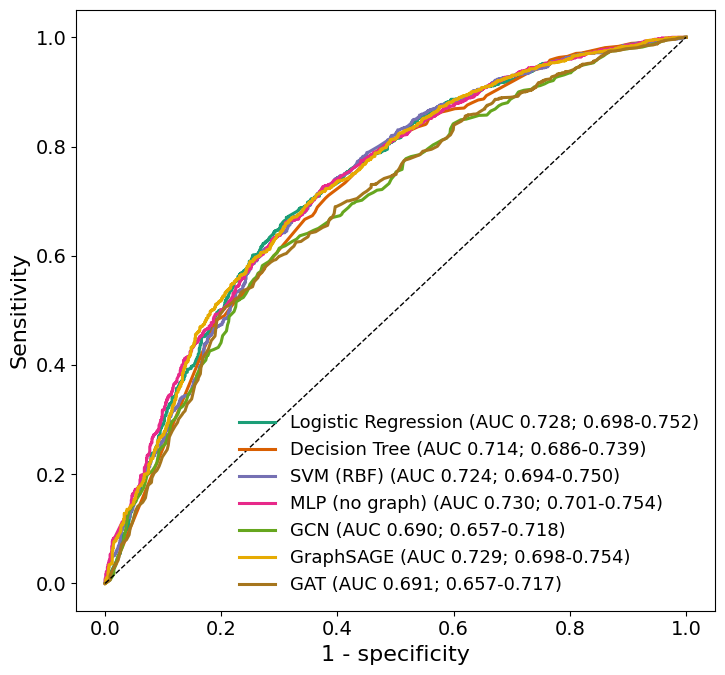

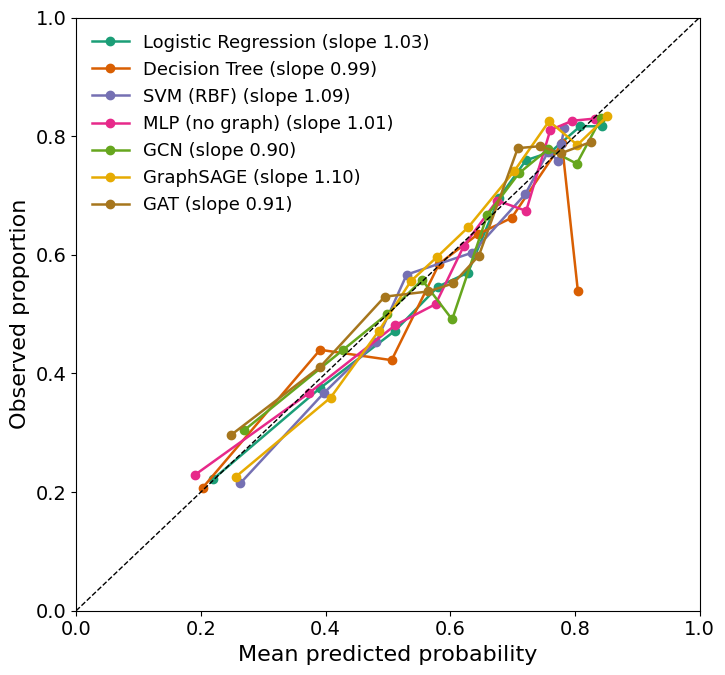

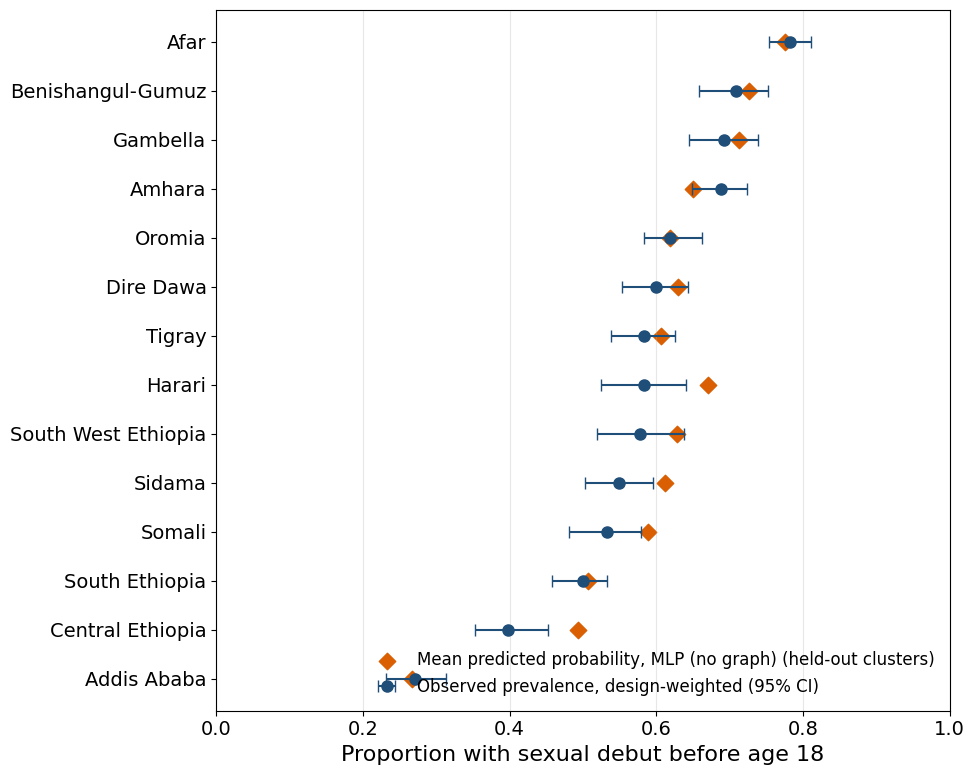

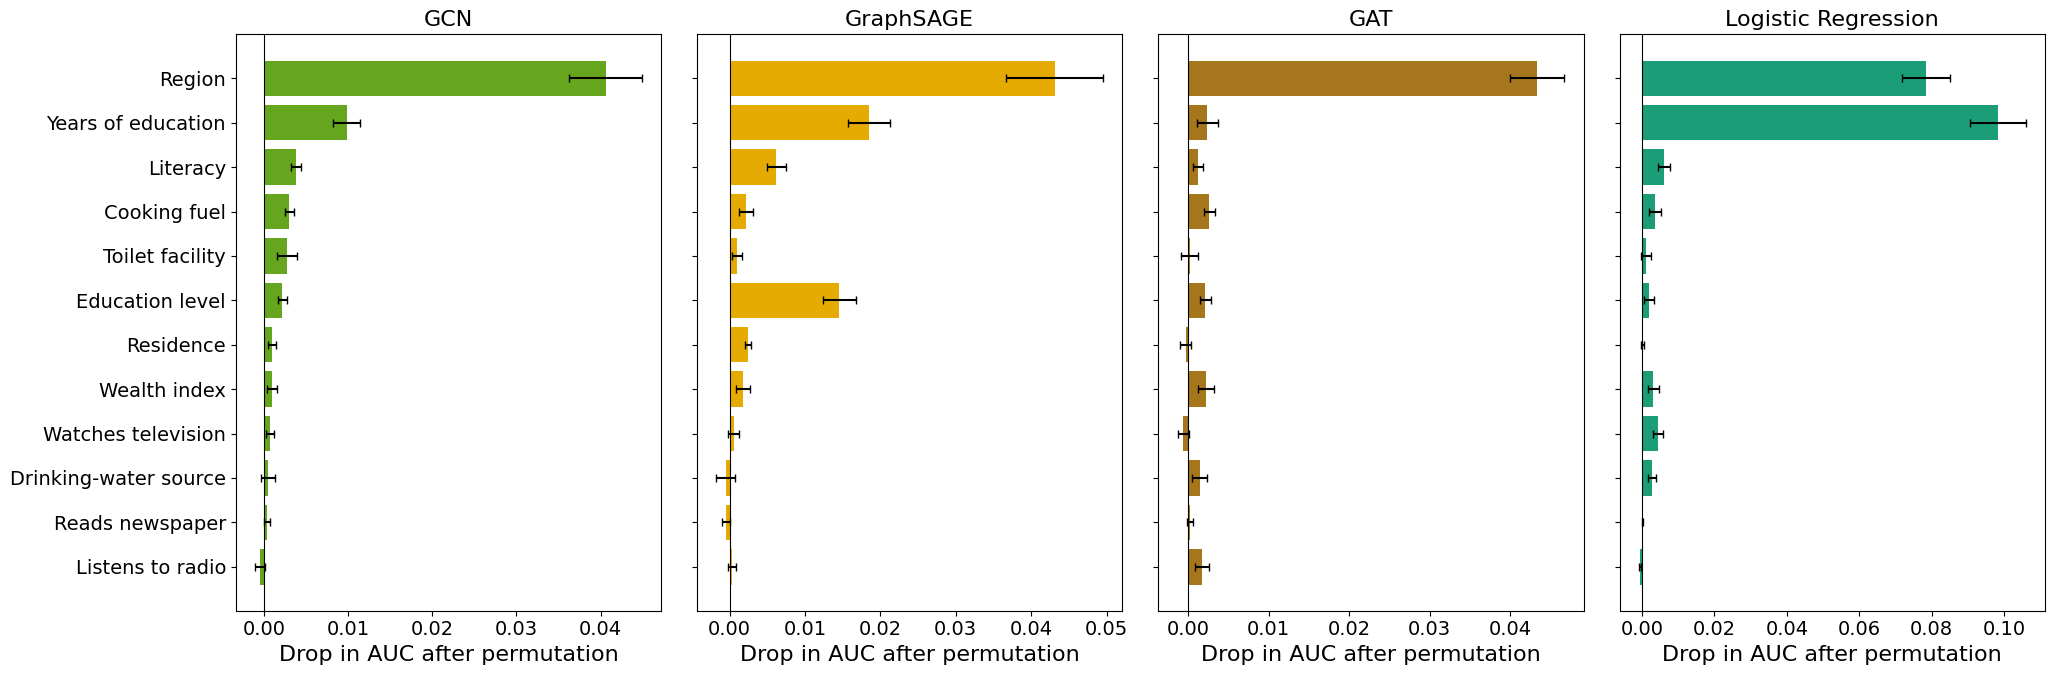

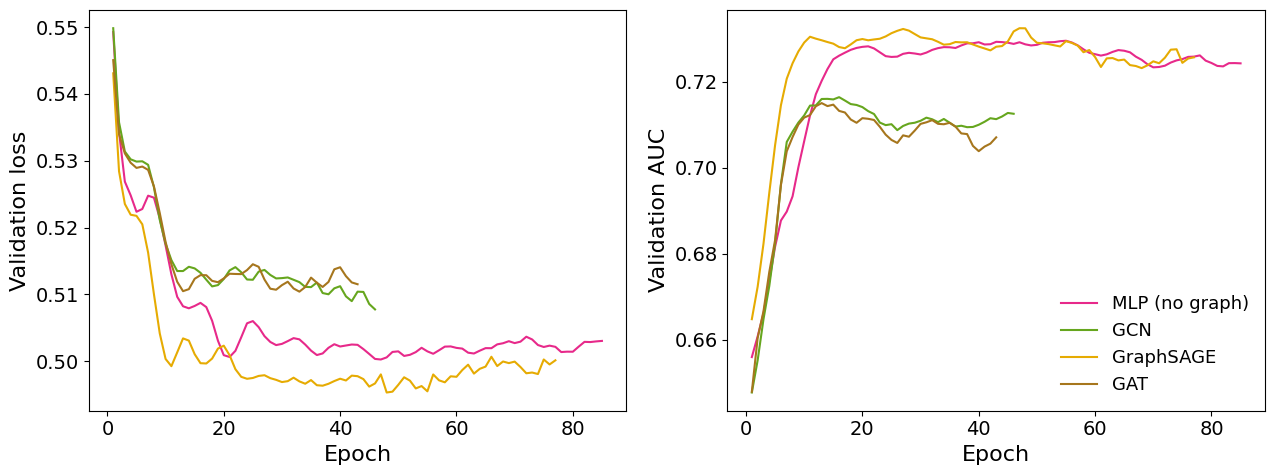

boundaries from geoBoundaries 2016 https://github.com/wmgeolab/geoBoundaries/raw/9469f09/releaseData/gbOpen/ETH/ADM1/geoBoundaries-ETH-ADM1_simplified.geojson


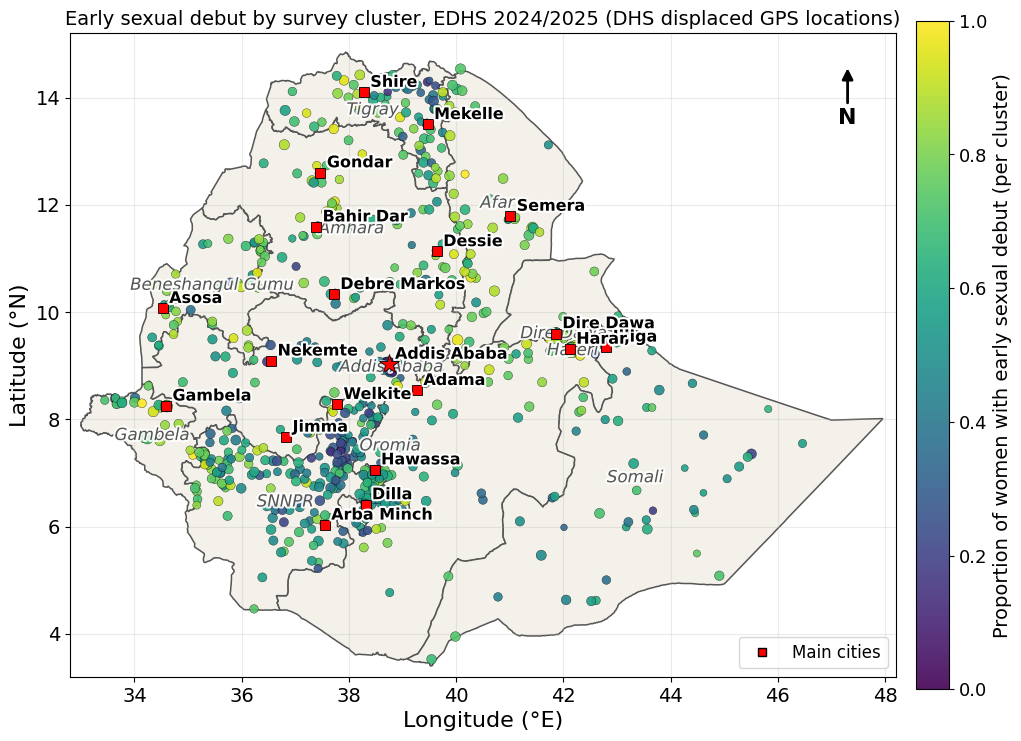

figures saved: ['fig_calibration.png', 'fig_importance.png', 'fig_learning.png', 'fig_map.png', 'fig_region.png', 'fig_roc.png']


In [ ]:
# ---- Figures (large fonts for readability) ----
import matplotlib; import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
plt.rcParams.update({'font.size': 15, 'axes.labelsize': 16, 'axes.titlesize': 16, 'legend.fontsize': 13, 'xtick.labelsize': 14, 'ytick.labelsize': 14})
os.makedirs('figures', exist_ok=True)
P, yte = PRIMARY['_P'], PRIMARY['_yte']; names = list(P)
COL = dict(zip(names, ['#1b9e77', '#d95f02', '#7570b3', '#e7298a', '#66a61e', '#e6ab02', '#a6761d', '#666666']))
# Fig: ROC curves
fig, ax = plt.subplots(figsize=(7.5, 7))
for n in names:
    f, t, _ = roc_curve(yte, P[n]); ci = PRIMARY['boot']['auc_ci'][n]
    ax.plot(f, t, lw=2.2, color=COL[n], label=f"{n} (AUC {PRIMARY['models'][n]['auc']:.3f}; {ci[0]:.3f}-{ci[1]:.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_xlabel('1 - specificity'); ax.set_ylabel('Sensitivity'); ax.legend(loc='lower right', frameon=False)
fig.tight_layout(); fig.savefig('figures/fig_roc.png', dpi=200); plt.show()
# Fig: calibration (deciles of predicted probability, held-out test clusters)
fig, ax = plt.subplots(figsize=(7.5, 7))
for n in names:
    q = pd.qcut(P[n], 10, duplicates='drop'); g = pd.DataFrame({'p': P[n], 'y': yte}).groupby(q, observed=True).mean()
    ax.plot(g.p, g.y, 'o-', lw=1.8, ms=6, color=COL[n], label=f"{n} (slope {PRIMARY['models'][n]['calib_slope']:.2f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Observed proportion'); ax.legend(frameon=False, loc='upper left')
fig.tight_layout(); fig.savefig('figures/fig_calibration.png', dpi=200); plt.show()
# Fig: regional design-weighted prevalence (with 95% CI) vs mean predicted probability of the best-AUC model in held-out clusters
best = max(names, key=lambda n: PRIMARY['models'][n]['auc'])
pw = RES['prev_weighted']['region']; regs = sorted(pw, key=lambda r: pw[r][0]); yy = np.arange(len(regs))
fig, ax = plt.subplots(figsize=(10, 8))
ax.errorbar([pw[r][0] for r in regs], yy, xerr=[[pw[r][0]-pw[r][1] for r in regs], [pw[r][2]-pw[r][0] for r in regs]], fmt='o', color='#1f4e79', capsize=4, ms=8, label='Observed prevalence, design-weighted (95% CI)')
ax.scatter([PRIMARY['region_test'][r][best] if r in PRIMARY['region_test'] else np.nan for r in regs], yy, marker='D', s=70, color='#d95f02', label=f'Mean predicted probability, {best} (held-out clusters)')
ax.set_yticks(yy); ax.set_yticklabels(regs); ax.set_xlabel('Proportion with sexual debut before age 18'); ax.set_xlim(0, 1); ax.legend(loc='lower right', frameon=False, fontsize=12); ax.grid(axis='x', alpha=.3)
fig.tight_layout(); fig.savefig('figures/fig_region.png', dpi=200); plt.show()
# Fig: predictor importance (mean drop in test AUC, error bars = SD over 30 permutations), one panel per model
shown = [n for n in ['GCN', 'GraphSAGE', 'GAT', 'Logistic Regression'] if n in P] or names[:1]
fig, axs = plt.subplots(1, len(shown), figsize=(5.2*len(shown), 7), sharey=True); axs = np.atleast_1d(axs)
order = sorted(NUM + CAT, key=lambda c: PRIMARY['perm_importance'][shown[0]][c][0])
for ax, n in zip(axs, shown):
    ax.barh([PRED_LABELS[c] for c in order], [PRIMARY['perm_importance'][n][c][0] for c in order], xerr=[PRIMARY['perm_importance'][n][c][1] for c in order], color=COL[n], capsize=3)
    ax.set_title(n); ax.set_xlabel('Drop in AUC after permutation'); ax.axvline(0, color='k', lw=.8)
fig.tight_layout(); fig.savefig('figures/fig_importance.png', dpi=200); plt.show()
# Fig: learning curves of the graph models
if PRIMARY['_curves']:
    fig, axs = plt.subplots(1, 2, figsize=(13, 5))
    for n, h in PRIMARY['_curves'].items():
        h = np.array(h); axs[0].plot(h[:, 0], h[:, 2], color=COL[n], label=n); axs[1].plot(h[:, 0], h[:, 3], color=COL[n], label=n)
    axs[0].set_xlabel('Epoch'); axs[0].set_ylabel('Validation loss'); axs[1].set_xlabel('Epoch'); axs[1].set_ylabel('Validation AUC'); axs[1].legend(frameon=False)
    fig.tight_layout(); fig.savefig('figures/fig_learning.png', dpi=200); plt.show()
# Fig: map of cluster-level prevalence on real Ethiopian boundaries (code in the previous cell)
draw_map(cl)
print('figures saved:', sorted(os.listdir('figures')))

## 10. Export results
Send `results.json` back to regenerate the manuscript tables automatically.

In [ ]:
# ---- Export every number used in the manuscript ----
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
json.dump(_clean(RES), open('results.json', 'w'), indent=1)
pd.DataFrame(RES['primary']['models']).T.round(4).to_csv('table_model_performance.csv')
print('saved results.json, table_model_performance.csv and figures/ ; download them (and send results.json back to update the manuscript).')
try:
    from google.colab import files
    import shutil; shutil.make_archive('revision_outputs', 'zip', '.', 'figures'); files.download('results.json'); files.download('revision_outputs.zip')
except Exception: pass

saved results.json, table_model_performance.csv and figures/ ; download them (and send results.json back to update the manuscript).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>